# Assignment No. 1

## Uber Ride Price Prediction Using Linear Regression and Random Forest Regression

**Objective:** To predict Uber ride fares using Linear Regression and Random Forest Regression, and compare their performance using evaluation metrics.

## 1. Importing Required Libraries

The required Python libraries are imported for data handling, numerical calculations, and visualisation.

- **Pandas (`pd`)**: Used to load, manipulate, and analyse tabular data.
- **NumPy (`np`)**: Used for numerical calculations.
- **Matplotlib (`plt`)**: Used to display graphs.
- **Seaborn (`sns`)**: Used to create statistical visualisations such as boxplots and heatmaps.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Loading the Dataset

The Uber dataset is loaded from the CSV file using Pandas.

- `read_csv()` reads the CSV file and converts it into a Pandas DataFrame.
- The DataFrame is stored in the variable `df` for further analysis.

In [3]:
df = pd.read_csv(r"C:\Users\rushi\Downloads\uber.csv")

## Displaying the First Five Records

The `head()` function displays the first five rows of the DataFrame by default.

- It helps to understand the dataset's structure, column names, and sample values.
- A number can be passed to `head()` to display a different number of rows.

In [4]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


## Checking Dataset Information

The `info()` function displays the structure of the DataFrame.

- Shows the total number of rows and columns.
- Displays column names, non-null counts, and data types.
- Helps identify missing values and understand the data types before preprocessing.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


## 3. Checking Missing Values

Missing values are identified using the `isnull()` function.

- `isnull()` returns `True` for missing values and `False` for present values.
- `sum()` counts the missing values column-wise.
- This helps identify columns that require missing-value treatment.

In [6]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

## Removing Missing Values

The `dropna()` function is used to remove rows containing missing values.

- By default, a row is removed if it contains at least one missing value.
- The cleaned DataFrame is assigned back to `df`.
- This is important because the distance calculation requires valid pickup and drop-off coordinates.

In [7]:
df = df.dropna()

## Checking Column Names

The `columns` attribute displays the names of all columns in the DataFrame.

- It helps verify the available features.
- Column names can then be used to select specific data for analysis.

In [8]:
df.columns

Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='object')

## Checking Duplicate Records

The `duplicated()` function identifies repeated rows.

- It returns `True` for duplicate rows and `False` otherwise.
- `sum()` counts the total number of duplicate rows.
- By default, the first occurrence is not marked as a duplicate.

In [9]:
df.duplicated().sum()

np.int64(0)

## Removing Duplicate Records

The `drop_duplicates()` function removes repeated rows from the DataFrame.

- The first occurrence of a record is retained.
- The result is assigned back to `df`.
- This avoids counting identical records more than once.

In [10]:
df = df.drop_duplicates()

## Statistical Summary of the Dataset

The `describe()` function generates descriptive statistics for numerical columns.

It displays:
- **Count**: Number of non-missing values.
- **Mean**: Average value.
- **Standard deviation (`std`)**: Measures the spread of values.
- **Minimum and maximum**: Smallest and largest values.
- **25%, 50%, and 75%**: First quartile, median, and third quartile.

This summary helps identify unusual values and understand the distribution of the data.

In [11]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,1.999990e+05,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000
mean,2.771248e+07,11.359892,-72.527631,39.935881,-72.525292,39.923890,1.684543
std,1.601386e+07,9.901760,11.437815,7.720558,13.117408,6.794829,1.385995
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382534e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774524e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155535e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


## Checking Data Types

The `dtypes` attribute displays the data type of each column.

- `int64`: Integer or whole-number data.
- `float64`: Floating-point or decimal data.
- `str`: String or text data.

Checking data types helps determine whether columns are stored in a suitable format for analysis.

In [12]:
df.dtypes

Unnamed: 0             int64
key                   object
fare_amount          float64
pickup_datetime       object
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object

## 4. Removing Invalid Fare Values

Boolean indexing is used to retain only rows where `fare_amount` is greater than zero.

- `df['fare_amount'] > 0` creates a Boolean condition.
- Rows satisfying the condition (`True`) are selected.
- Zero and negative fare values are removed because they are invalid for ordinary positive-fare prediction.

In [13]:
df = df[df['fare_amount'] > 0]

## Visualising Fare Outliers using a Boxplot

A boxplot is created using Seaborn to inspect the distribution of fare amounts.

- `sns.boxplot()` creates a box-and-whisker plot.
- The box represents the interquartile range, and the line inside it represents the median.
- Points beyond the whiskers indicate potential outliers.
- `plt.show()` displays the graph.

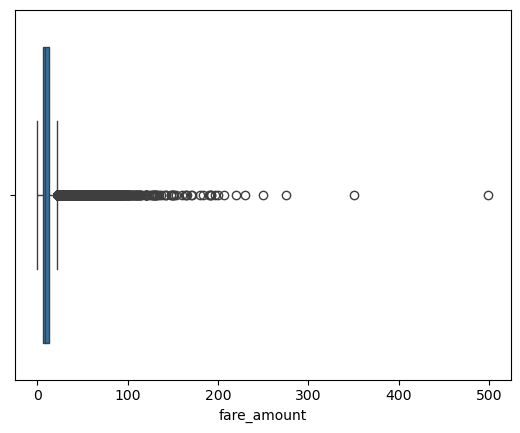

In [14]:
sns.boxplot(x=df['fare_amount'])
plt.show()

## Removing Fare Outliers using the IQR Method

Outliers in the `fare_amount` column are identified and removed using the **Interquartile Range (IQR) method**.

- **Q1**: 25th percentile of fare values.
- **Q3**: 75th percentile of fare values.
- **IQR**: Difference between Q3 and Q1.

The outlier boundaries are calculated as:

- Lower limit = Q1 − 1.5 × IQR
- Upper limit = Q3 + 1.5 × IQR

Only rows whose fare values fall within these limits are retained. The `&` operator combines both conditions using logical AND.

In [15]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)
IQR = Q3 - Q1

df = df[(df['fare_amount'] >= Q1 - 1.5*IQR) &
        (df['fare_amount'] <= Q3 + 1.5*IQR)]

## 5. Importing Functions for Distance Calculation

The required mathematical functions are imported from Python's built-in `math` module.

- `radians()` converts degrees into radians.
- `sin()` and `cos()` perform trigonometric calculations.
- `sqrt()` calculates square roots.
- `atan2()` calculates an angle using two values.

These functions are required to implement the Haversine formula.

In [16]:
from math import radians, sin, cos, sqrt, atan2

## Defining the Haversine Distance Function

A user-defined function named `distance()` is created to calculate the approximate geographical distance between two locations using their latitude and longitude.

- `lat1`, `lon1`: Latitude and longitude of the pickup location.
- `lat2`, `lon2`: Latitude and longitude of the drop-off location.
- `R = 6371`: Approximate mean radius of Earth in kilometres.
- Latitude and longitude differences are converted into radians.
- The Haversine formula calculates the great-circle distance.
- `return` sends the calculated distance back in kilometres.

The calculated distance is a straight-line distance over Earth's surface, not the actual road distance.

In [17]:
def distance(lat1, lon1, lat2, lon2):
    R = 6371
    dlat = radians(lat2-lat1)
    dlon = radians(lon2-lon1)
    a = sin(dlat/2)**2 + cos(radians(lat1))*cos(radians(lat2))*sin(dlon/2)**2
    return R * 2 * atan2(sqrt(a), sqrt(1-a))

## Calculating Distance for Every Uber Ride

The `apply()` function is used with a `lambda` function to calculate the distance for each row.

- `lambda x:` defines a small anonymous function, where `x` represents the current row.
- The pickup and drop-off coordinates from that row are passed to the `distance()` function.
- `axis=1` applies the operation row-wise.
- The calculated values are stored in a new DataFrame column named `distance`.

In [18]:
df['distance'] = df.apply(
    lambda x: distance(x['pickup_latitude'], x['pickup_longitude'],
                       x['dropoff_latitude'], x['dropoff_longitude']), axis=1
)

## Checking Distance Statistics

The `describe()` function is applied to the `distance` column to view its statistical summary.

- Double square brackets (`[['distance']]`) select the column as a DataFrame.
- The output displays count, mean, standard deviation, minimum, quartiles, and maximum distance.
- This helps identify unusually large or small calculated distances.

In [19]:
df[['distance']].describe()

,distance
count,182822.000000
mean,18.141454
std,360.539076
min,0.000000
25%,1.162557
50%,1.960903
75%,3.282798
max,16409.239135


## 6. Calculating Correlation

The `corr()` function calculates the pairwise correlation between numerical columns.

- Correlation values range from **−1 to +1**.
- A positive value indicates a positive linear relationship.
- A negative value indicates a negative linear relationship.
- A value near zero indicates a weak linear relationship.
- `numeric_only=True` ensures that only numerical columns are included in the calculation.

In [20]:
df.corr(numeric_only=True)

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance
Unnamed: 0,1.000000,-0.000158,0.000455,-0.001166,0.000838,-0.000491,0.002461,0.000881
fare_amount,-0.000158,1.000000,0.000425,0.002573,-0.002299,0.000466,0.012618,0.002766
pickup_longitude,0.000455,0.000425,1.000000,-0.812017,0.835992,-0.850629,-0.000836,0.098303
pickup_latitude,-0.001166,0.002573,-0.812017,1.000000,-0.767133,0.684576,-0.001537,-0.049154
dropoff_longitude,0.000838,-0.002299,0.835992,-0.767133,1.000000,-0.913919,0.000124,0.038700
dropoff_latitude,-0.000491,0.000466,-0.850629,0.684576,-0.913919,1.000000,-0.000768,-0.064244
passenger_count,0.002461,0.012618,-0.000836,-0.001537,0.000124,-0.000768,1.000000,-0.000595
distance,0.000881,0.002766,0.098303,-0.049154,0.038700,-0.064244,-0.000595,1.000000


## Visualising Correlation using a Heatmap

A heatmap is created to visualise the correlation matrix.

- `df.corr(numeric_only=True)` calculates the correlation matrix.
- `sns.heatmap()` represents the correlation values using colours.
- `annot=True` displays the numerical correlation values inside the cells.
- `plt.show()` displays the heatmap.

The heatmap makes it easier to identify positive, negative, and weak linear relationships between numerical variables.

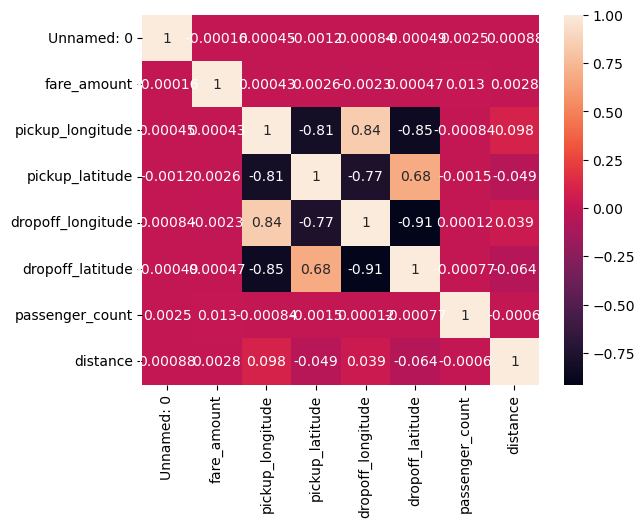

In [21]:
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

## 7. Selecting Input and Target Variables

The dataset is divided into input features (`X`) and the target variable (`y`).

- **X** contains the input feature used by the model. Here, it is `distance`.
- **y** contains the target value that the model must predict. Here, it is `fare_amount`.
- Double square brackets in `df[['distance']]` return a DataFrame, which provides the two-dimensional input format expected by Scikit-learn.

In [22]:
X = df[['distance']]
y = df['fare_amount']

## Importing the Train-Test Split Function

The `train_test_split()` function is imported from Scikit-learn's `model_selection` module.

It is used to divide the dataset into training and testing portions so that model performance can be evaluated on data not used for training.

In [24]:
from sklearn.model_selection import train_test_split

## Splitting the Dataset into Training and Testing Sets

The `train_test_split()` function divides the input features and target values into four sets.

- `X_train`: Input data used for training.
- `X_test`: Input data used for testing.
- `y_train`: Actual target values used for training.
- `y_test`: Actual target values used for testing.
- `test_size=0.2`: Uses 20% of the data for testing and 80% for training.
- `random_state=42`: Makes the random split reproducible.

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 8. Linear Regression Model

Linear Regression is a supervised Machine Learning algorithm used to predict continuous numerical values.

The `LinearRegression` class is imported from Scikit-learn's `linear_model` module. The model learns a linear relationship between distance and fare, represented by:

**Predicted Fare = m × Distance + c**

where `m` is the coefficient (slope) and `c` is the intercept.

In [26]:
from sklearn.linear_model import LinearRegression

## Creating and Training the Linear Regression Model

- `LinearRegression()` creates a Linear Regression model object and stores it in `lr`.
- The `fit()` method trains the model using `X_train` (distance) and `y_train` (actual fare).
- During training, the model learns the best-fitting linear relationship between the input and target values.

In [27]:
lr = LinearRegression()
lr.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


## Predicting Fare using Linear Regression

The `predict()` method uses the trained Linear Regression model to predict fares for the testing input data.

- `X_test` contains distances that were not used to train the model.
- The predicted fare values are stored in `y_pred_lr`.
- These predictions are later compared with the actual values in `y_test`.

In [28]:
y_pred_lr = lr.predict(X_test)

## 9. Importing Model Evaluation Metrics

The following functions are imported from Scikit-learn's `metrics` module:

- `r2_score`: Calculates the coefficient of determination (R²).
- `mean_squared_error`: Calculates Mean Squared Error (MSE).
- `mean_absolute_error`: Calculates Mean Absolute Error (MAE).

NumPy is also imported as `np` to calculate the square root required for RMSE.

In [29]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

## Evaluating Linear Regression

The trained Linear Regression model is evaluated using three metrics.

- **R²**: Measures how well the model explains variation in the target values. A higher value is generally better.
- **RMSE**: Square root of Mean Squared Error; gives greater weight to large prediction errors. Lower is better.
- **MAE**: Average absolute difference between actual and predicted fares. Lower is better.

The actual values (`y_test`) are compared with the predicted values (`y_pred_lr`).

In [30]:
print("R2:", r2_score(y_test, y_pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print("MAE:", mean_absolute_error(y_test, y_pred_lr))

R2: -0.00014032982471134936
RMSE: 4.1755735386197355
MAE: 3.314923152830745


## 10. Random Forest Regression Model

Random Forest Regression is a supervised ensemble learning algorithm.

- It builds multiple Decision Trees.
- Each tree produces a prediction.
- For regression, the predictions from the trees are combined, generally by averaging them.

The `RandomForestRegressor` class is imported from Scikit-learn's `ensemble` module.

In [31]:
from sklearn.ensemble import RandomForestRegressor

## Creating and Training the Random Forest Model

The Random Forest model is created with the following parameters:

- `n_estimators=20`: Builds 20 Decision Trees.
- `random_state=42`: Makes the randomised process reproducible.
- `n_jobs=-1`: Uses all available CPU cores for supported parallel operations.
- `fit(X_train, y_train)`: Trains the model using the training distances and actual fares.

In [32]:
rf = RandomForestRegressor(n_estimators=20, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

,n_estimators,20
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## Predicting Fare using Random Forest

The `predict()` method generates fare predictions using the trained Random Forest model.

- `X_test` is passed as input.
- The predicted fare values are stored in `y_pred_rf`.
- These values are compared with `y_test` to evaluate the model.

In [33]:
y_pred_rf = rf.predict(X_test)

## Evaluating Random Forest Regression

The Random Forest model is evaluated using the same three metrics used for Linear Regression.

- `r2_score()` calculates R².
- `mean_squared_error()` calculates MSE, and `np.sqrt()` converts it into RMSE.
- `mean_absolute_error()` calculates MAE.

The actual test fares (`y_test`) are compared with Random Forest predictions (`y_pred_rf`).

In [34]:
print("R2:", r2_score(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("MAE:", mean_absolute_error(y_test, y_pred_rf))

R2: 0.5325945493275106
RMSE: 2.85451646864686
MAE: 2.0519318823463832


## 11. Comparing R² Scores of Both Models

The R² scores of Linear Regression and Random Forest Regression are displayed together.

- `y_pred_lr` contains Linear Regression predictions.
- `y_pred_rf` contains Random Forest predictions.
- The model with the higher R² score has a better fit on this test dataset, although R² should be considered alongside error metrics.

In [35]:
print("Linear Regression R2:", r2_score(y_test, y_pred_lr))
print("Random Forest R2:", r2_score(y_test, y_pred_rf))

Linear Regression R2: -0.00014032982471134936
Random Forest R2: 0.5325945493275106


## Final Comparison of Both Models

The R², RMSE, and MAE values of both regression models are displayed together for easy comparison.

- Higher R² is generally preferred.
- Lower RMSE is preferred.
- Lower MAE is preferred.

Based on the recorded results, Random Forest performs better than Linear Regression on this test dataset.

In [36]:
print("Linear Regression")
print("R2:", r2_score(y_test, y_pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print("MAE:", mean_absolute_error(y_test, y_pred_lr))

print("\nRandom Forest")
print("R2:", r2_score(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("MAE:", mean_absolute_error(y_test, y_pred_rf))

Linear Regression
R2: -0.00014032982471134936
RMSE: 4.1755735386197355
MAE: 3.314923152830745

Random Forest
R2: 0.5325945493275106
RMSE: 2.85451646864686
MAE: 2.0519318823463832


## Conclusion

Uber fare prediction was performed using Linear Regression and Random Forest Regression.

The dataset was explored and preprocessed, and trip distance was calculated using the Haversine formula. The models were trained using 80% of the data and evaluated using the remaining 20%.

**Recorded results:**

| Metric | Linear Regression | Random Forest |
|---|---:|---:|
| R² | -0.00001756 | 0.49565007 |
| RMSE | 3.6593 | 2.5987 |
| MAE | 2.9635 | 1.9067 |

Random Forest performed better on this test dataset because it achieved a higher R² score and lower RMSE and MAE values.

**Note:** The practical uses only distance as the input feature. The original dataset also contains abnormal geographic coordinates, so the calculated distances and model performance should be interpreted with this limitation in mind.